In [1]:
from auxin_signalling_pathway.reduced_auxin_signalling_pathway import \
    reduced_auxin_signalling_pathway as reduced_asp_class
from auxin_signalling_pathway import auxin_signalling_pathway as asp_class

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

In [2]:
kwargs = {'nARFs': 1, 'nIAAs': 1}

asp_model_r = reduced_asp_class(**kwargs)
asp_model_full = asp_class(**kwargs)
asp_model_full.remove_state('G__ARF_1')

In [3]:
# Find all parameters related to the promoter-protein dynamics
empty_set_node = asp_model_full.empty_set_node
aux_symbol = asp_model_full.aux_symbol

pp_reactions = []
promoter_symbols = [s for s in asp_model_full.get_state_variables() if s[0]=='G']
for r in asp_model_full._reactions_set:
    skip = False
    if r.enzymes:
        continue
    for s in list(r.products) + list(r.reactants):
        if s in [empty_set_node, aux_symbol]:
            skip = True
            break
    if skip:
        continue
    if [s for s in promoter_symbols if s in list(r.products) + list(r.reactants)]:
        pp_reactions.append(r)

pp_parameters = [s for r in pp_reactions for s in r.fwd_rates + r.bwd_rates]
print(asp_model_full.get_default_parameters())
print(pp_parameters)

{'arf__d': 1.0, 'arf__k': 1.0, 'd__D__ARF_1__ARF_1': 0.1, 'd__D__ARF_1__iaa_1': 0.1, 'd__D__iaa_1__iaa_1': 0.1, 'd__G__ARF_1': 0.01, 'd__G__ARF_1__ARF_1': 0.01, 'd__G__ARF_1__ARF_1__unbind__ARF_1': 0.0, 'd__G__ARF_1__iaa_1': 0.01, 'd__G__ARF_1__iaa_1__unbind__iaa_1': 0.0, 'd__R': 0.004166666666666667, 'd__iaa_1_x': 0.1, 'iaa__d': 1.0, 'iaa__k': 1.0, 'k__D__ARF_1__ARF_1': 0.001, 'k__D__ARF_1__iaa_1': 0.001, 'k__D__iaa_1__iaa_1': 0.001, 'k__G__ARF_1': 0.1, 'k__G__ARF_1__ARF_1': 0.1, 'k__G__ARF_1__ARF_1__R__iaa_1': 1.0, 'k__G__ARF_1__R__iaa_1': 1.0, 'k__G__ARF_1__bind__ARF_1': 0.0, 'k__G__ARF_1__bind__iaa_1': 0.0, 'k__G__ARF_1__iaa_1': 0.1, 'k__G__ARF_1__iaa_1__R__iaa_1': 1.0, 'k__G__R__iaa_1': 1.0, 'k__R': 0.01, 'k__R__iaa_1__iaa_1': 1.0, 'k__iaa_1': 0.0}
['k__G__ARF_1__ARF_1', 'd__G__ARF_1__ARF_1', 'k__G__ARF_1__iaa_1', 'd__G__ARF_1__iaa_1']


In [4]:
promoter_timeconstant = 'tau_G'
asp_model_full.add_transition_rate(promoter_timeconstant, 1.0, "Promoter timeconstant", strict=False)
full_parameter_subs_dict = asp_model_r.parameter_subs_dict.copy()

for p in pp_parameters:
    if p in full_parameter_subs_dict:
        print(f"{full_parameter_subs_dict[p]}")
    else:
        full_parameter_subs_dict[p] = sp.sympify(p) / sp.sympify(promoter_timeconstant)

print(full_parameter_subs_dict)

{'k__R__iaa_1__iaa_1': 'k__RNA__IAA', 'k__G__ARF_1__bind__ARF_1': 0.0, 'd__G__ARF_1__ARF_1__unbind__ARF_1': 0.0, 'k__G__ARF_1__bind__iaa_1': 0.0, 'd__G__ARF_1__iaa_1__unbind__iaa_1': 0.0, 'k__G__ARF_1__iaa_1__R__iaa_1': '0.5 * k__G__ARF_1__ARF_1_R__iaa_1', 'k__G__ARF_1__ARF_1': k__G__ARF_1__ARF_1/tau_G, 'd__G__ARF_1__ARF_1': d__G__ARF_1__ARF_1/tau_G, 'k__G__ARF_1__iaa_1': k__G__ARF_1__iaa_1/tau_G, 'd__G__ARF_1__iaa_1': d__G__ARF_1__iaa_1/tau_G}


{'k__R__iaa_1__iaa_1': 'k__RNA__IAA', 'k__G__ARF_1__bind__ARF_1': 0.0, 'd__G__ARF_1__ARF_1__unbind__ARF_1': 0.0, 'k__G__ARF_1__bind__iaa_1': 0.0, 'd__G__ARF_1__iaa_1__unbind__iaa_1': 0.0, 'k__G__ARF_1__iaa_1__R__iaa_1': '0.5 * k__G__ARF_1__ARF_1_R__iaa_1'}
{'k__R__iaa_1__iaa_1': 'k__RNA__IAA', 'k__G__ARF_1__bind__ARF_1': 0.0, 'd__G__ARF_1__ARF_1__unbind__ARF_1': 0.0, 'k__G__ARF_1__bind__iaa_1': 0.0, 'd__G__ARF_1__iaa_1__unbind__iaa_1': 0.0, 'k__G__ARF_1__iaa_1__R__iaa_1': '0.5 * k__G__ARF_1__ARF_1_R__iaa_1', 'k__G__ARF_1__ARF_1': k__G__ARF_1__ARF_1/tau_G, 'd__G__ARF_1__ARF_1': d__G__ARF_1__ARF_1/tau_G, 'k__G__ARF_1__iaa_1': k__G__ARF_1__iaa_1/tau_G, 'd__G__ARF_1__iaa_1': d__G__ARF_1__iaa_1/tau_G}
[Matrix([[-D__ARF_1__ARF_1*G*k__G__ARF_1__ARF_1 - D__ARF_1__iaa_1*G*k__G__ARF_1__iaa_1 + G__ARF_1__ARF_1*d__G__ARF_1__ARF_1 + G__ARF_1__iaa_1*d__G__ARF_1__iaa_1, D__ARF_1__ARF_1*G*k__G__ARF_1__ARF_1 - G__ARF_1__ARF_1*d__G__ARF_1__ARF_1, D__ARF_1__iaa_1*G*k__G__ARF_1__iaa_1 - G__ARF_1__iaa_1*d_

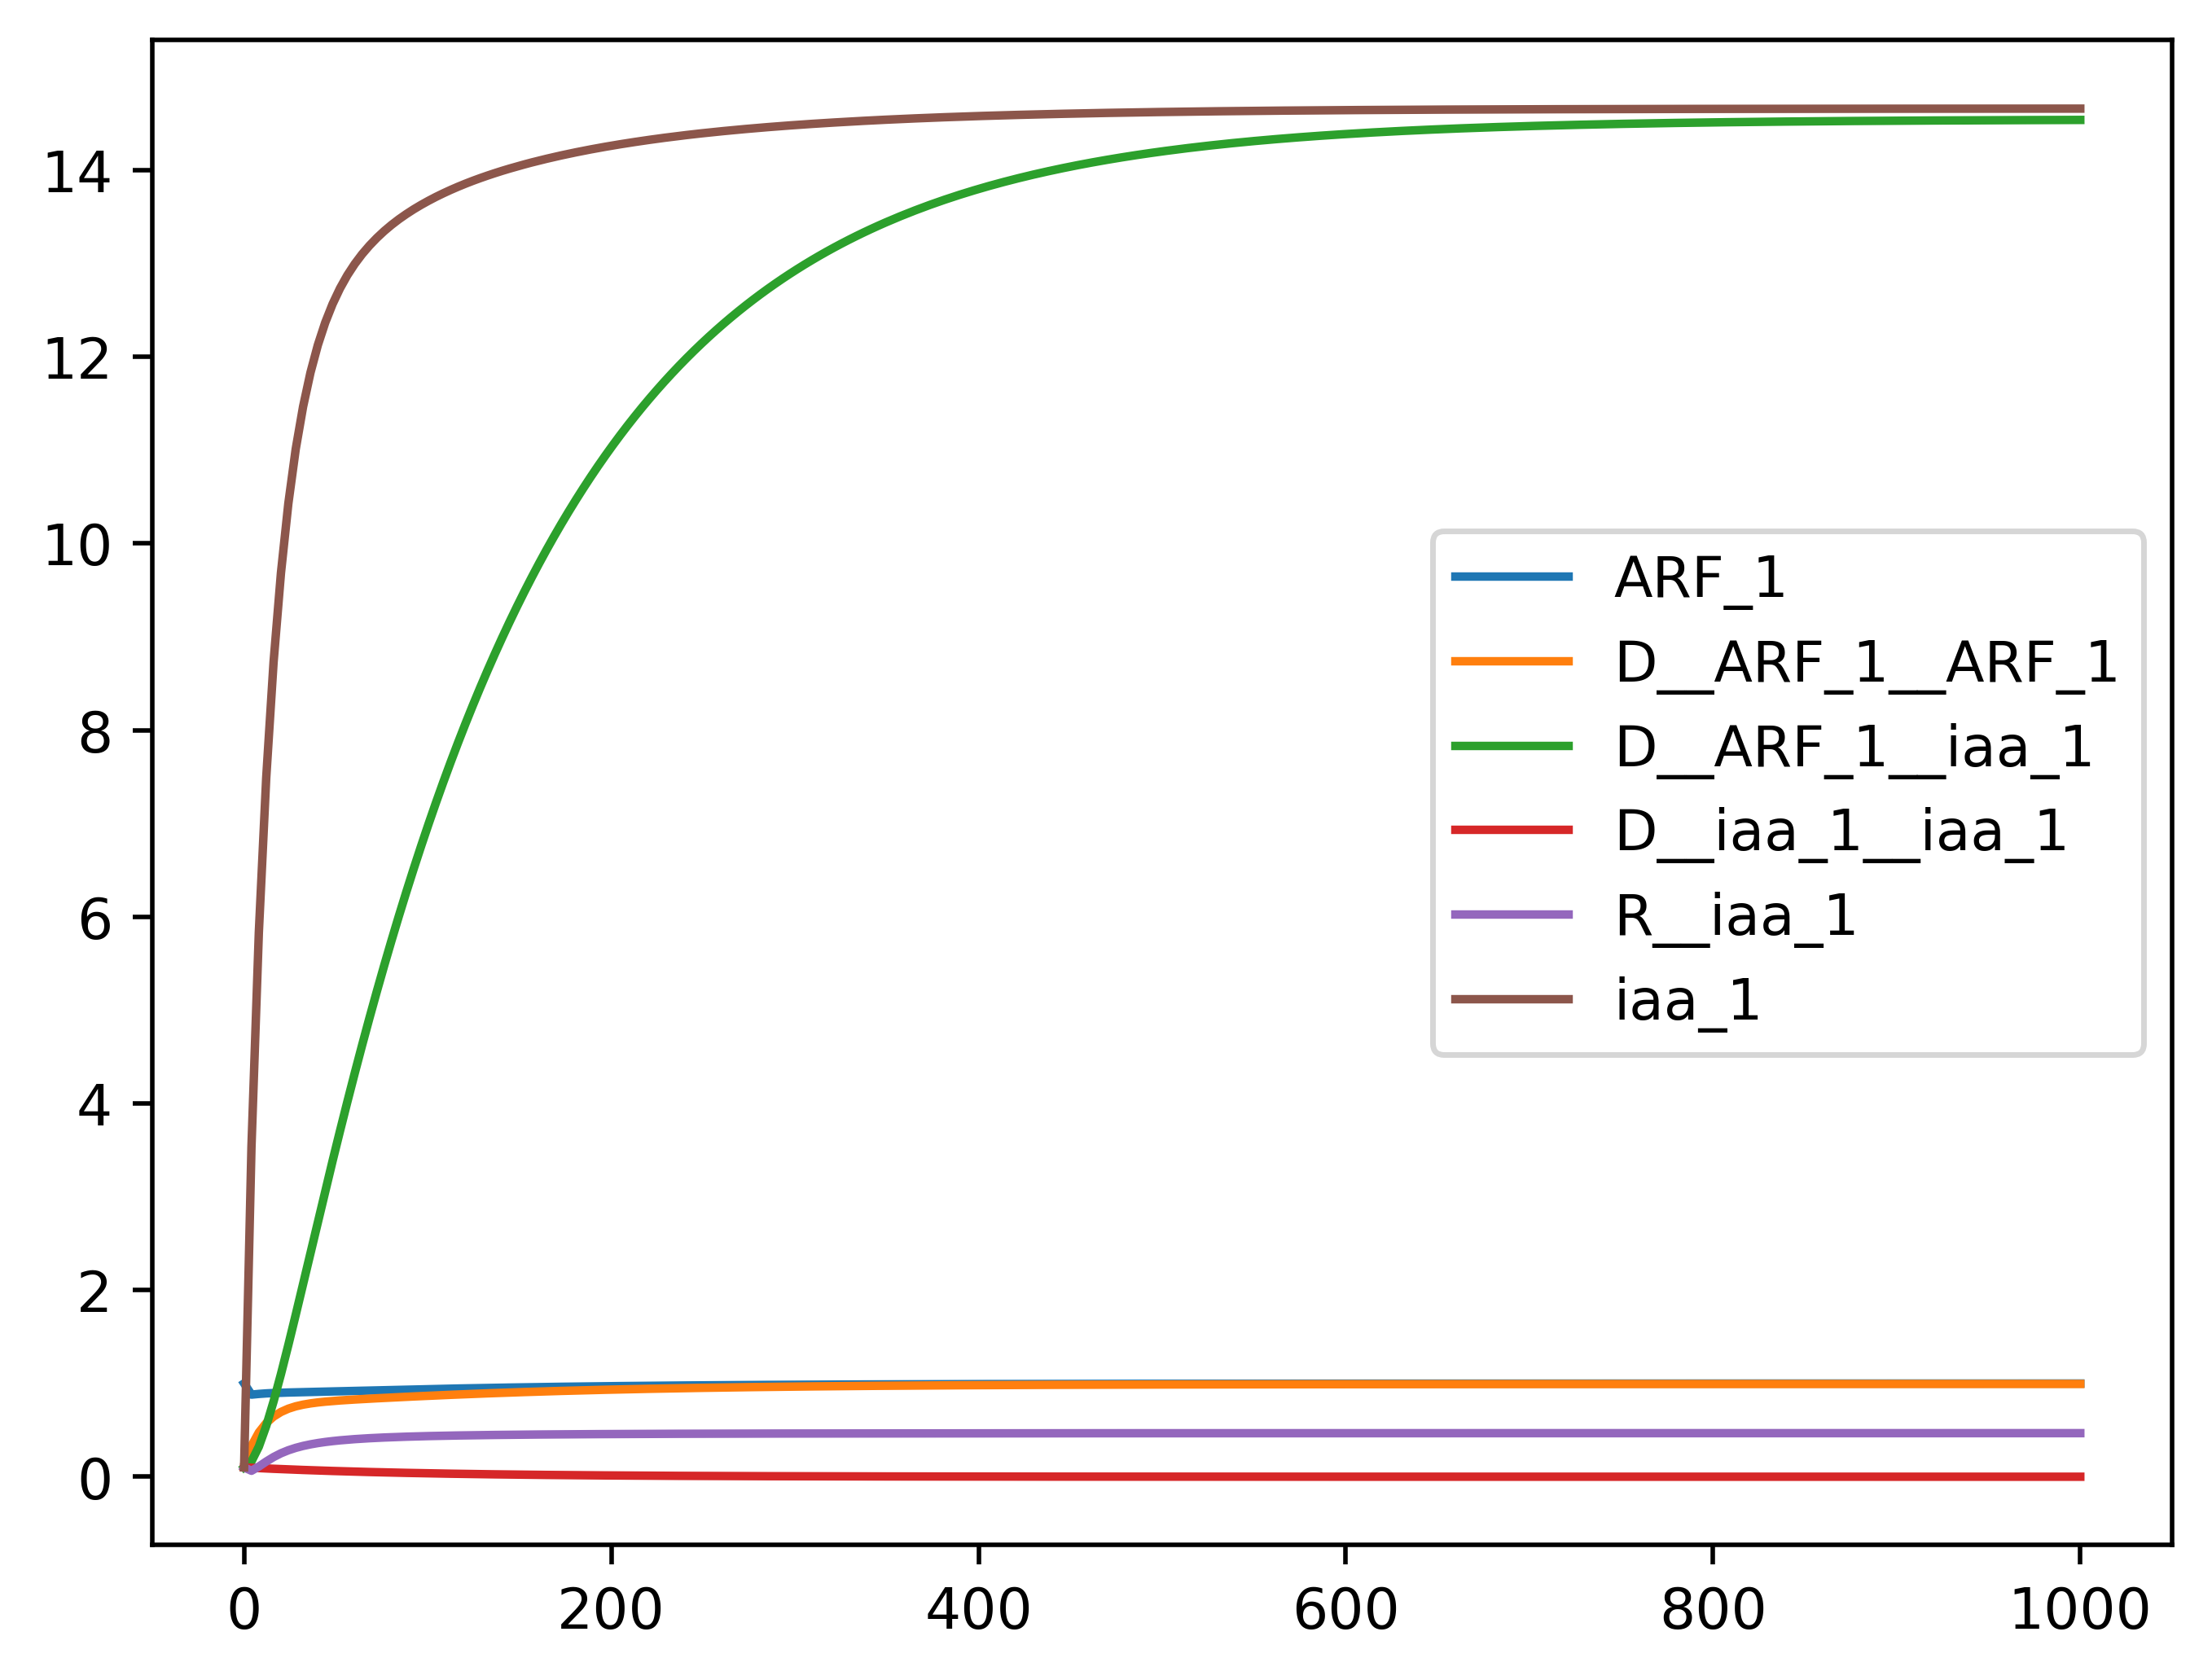

In [5]:
print(asp_model_r.parameter_subs_dict)
print(full_parameter_subs_dict)

reduced_solver = asp_model_r.make_forward_solver()
full_solver = asp_model_full.make_forward_solver(parameter_subs_dict=full_parameter_subs_dict)

print(full_parameter_subs_dict)

ts = np.linspace(0, 1000, 250)

reduced_param_dict = asp_model_r.get_default_parameters()
reduced_ic_dict = asp_model_r.get_default_initial_conditions()
full_ic_dict = asp_model_full.get_default_initial_conditions()

full_param_dict = reduced_param_dict.copy()

print(reduced_param_dict)
sol1, succ = reduced_solver(ts, reduced_param_dict, reduced_ic_dict, 1)
r_odes, free_variables, transition_rates, constraints = asp_model_r.generate_ode_system()

f_odes, free_variables, transition_rates, constraints = asp_model_full.generate_ode_system(parameter_subs_dict=full_parameter_subs_dict)

print(f_odes)

plt.plot(ts, sol1, label=reduced_ic_dict.keys())
# plt.plot(ts, sol1[:, -2], label=list(reduced_ic_dict.keys())[-2])
plt.legend()

{'0.5 * k__G__ARF_1__ARF_1_R__iaa_1': 1.0, 'arf__d': 1.0, 'arf__k': 1.0, 'd__D__ARF_1__ARF_1': 0.1, 'd__D__ARF_1__iaa_1': 0.1, 'd__D__iaa_1__iaa_1': 0.1, 'd__G__ARF_1': 0.01, 'd__G__ARF_1__ARF_1': 0.01, 'd__G__ARF_1__ARF_1__unbind__ARF_1': 0.0, 'd__G__ARF_1__iaa_1': 0.01, 'd__G__ARF_1__iaa_1__unbind__iaa_1': 0.0, 'd__R': 0.004166666666666667, 'd__iaa_1_x': 0.1, 'iaa__d': 1.0, 'iaa__k': 1.0, 'k__D__ARF_1__ARF_1': 0.001, 'k__D__ARF_1__iaa_1': 0.001, 'k__D__iaa_1__iaa_1': 0.001, 'k__G__ARF_1': 0.1, 'k__G__ARF_1__ARF_1': 0.1, 'k__G__ARF_1__ARF_1__R__iaa_1': 1.0, 'k__G__ARF_1__R__iaa_1': 1.0, 'k__G__ARF_1__bind__ARF_1': 0.0, 'k__G__ARF_1__bind__iaa_1': 0.0, 'k__G__ARF_1__iaa_1': 0.1, 'k__G__R__iaa_1': 1.0, 'k__R': 0.01, 'k__RNA__IAA': 1.0, 'k__iaa_1': 0.0, 'tau_G': 1e-10}
ARF_1*iaa_1*k__D__ARF_1__iaa_1 - D__ARF_1__iaa_1*G*k__G__ARF_1__iaa_1 - D__ARF_1__iaa_1*d__D__ARF_1__iaa_1


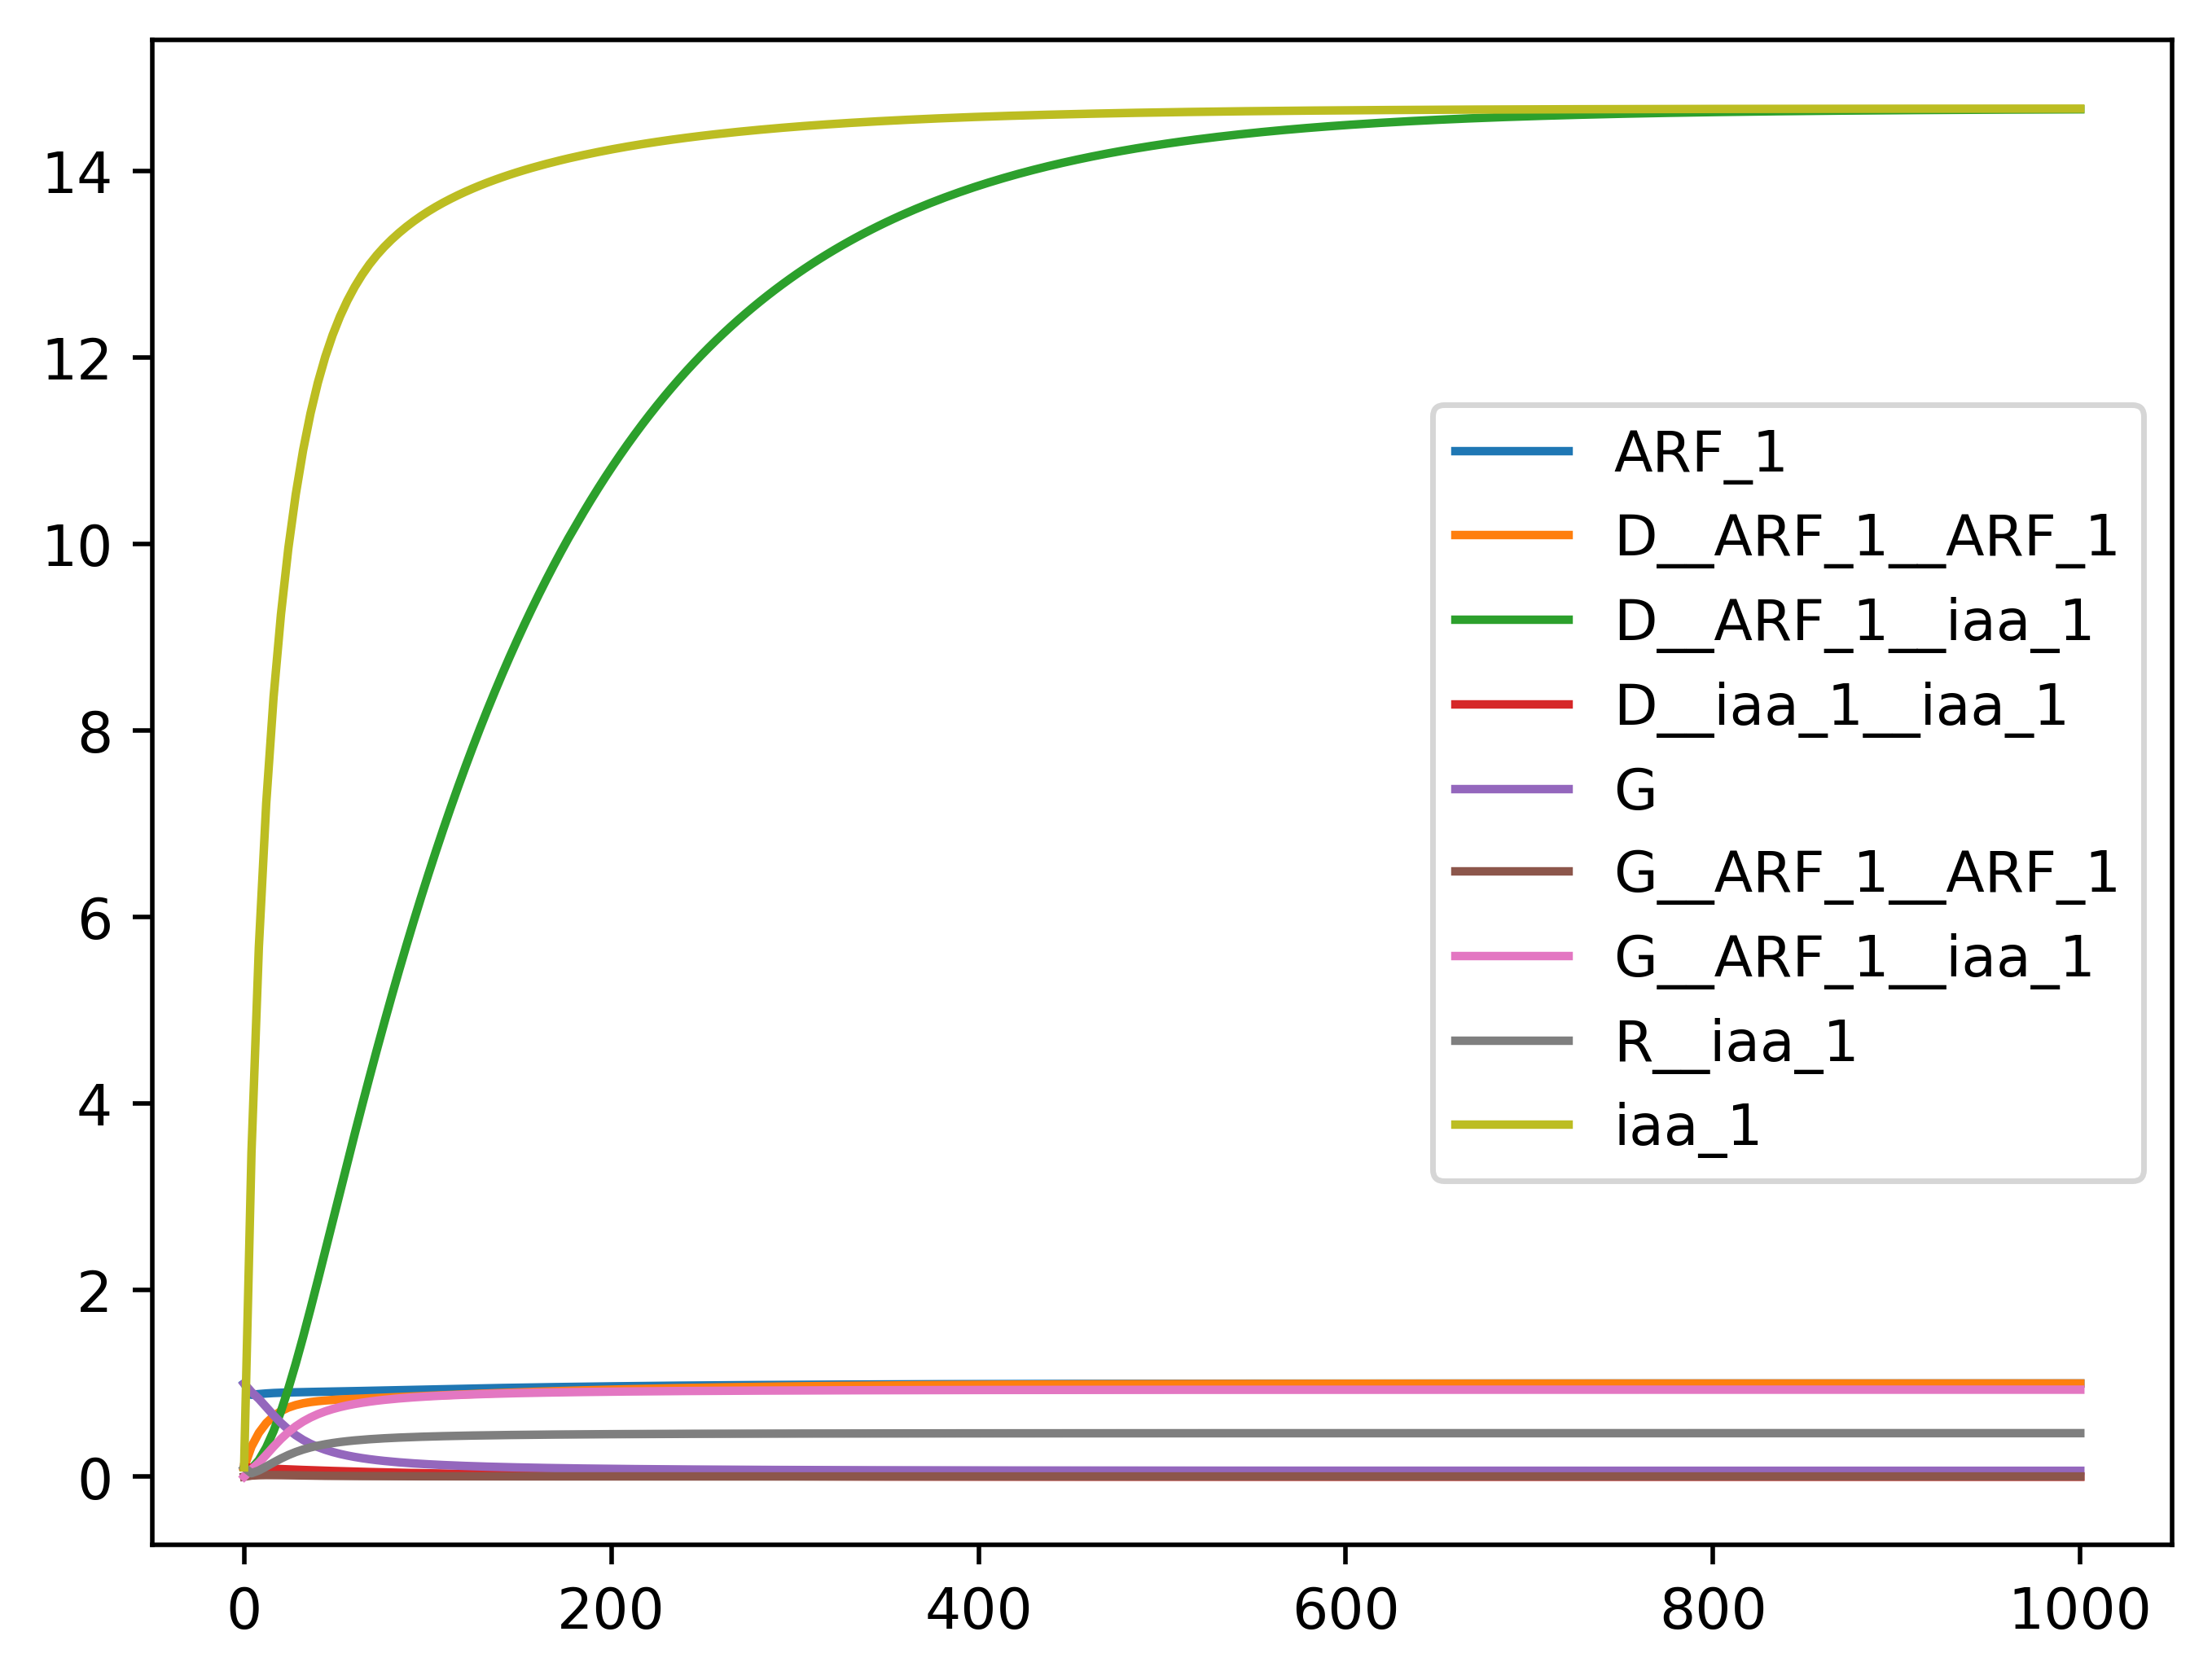

In [8]:
full_param_dict[promoter_timeconstant] = 1e-10
full_param_dict = {k: full_param_dict[k] for k in sorted(full_param_dict)}

print(full_param_dict)

sol2, succ = full_solver(ts, full_param_dict, full_ic_dict, 1)

plt.plot(ts, sol2, label=full_ic_dict.keys())
# plt.plot(ts, sol2[:, -2], label=list(full_ic_dict.keys())[-2])
plt.legend()

odes, free_variables, transition_rates, \
            _ = asp_model_r.generate_ode_system(
                                         reduced=True)
print(odes[2, 0])